In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [48]:
path = r'C:\Users\SART\Desktop\Practise\zameen.csv'

df = pd.read_csv(path)

df.head()

,Unnamed: 0,locations,sizes,beds,baths,time_added_text,prices
0,0,"DHA Phase 6 - Block K, DHA Phase 6",20,5.0,6.0,Added: 3 minutes ago,PKR9.85 Crore
1,1,"DHA 9 Town, DHA Defence",5,3.0,5.0,Added: 3 minutes ago,PKR2 Crore
2,2,"DHA Phase 7, DHA Defence",20,6.0,6.0,Added: 29 minutes ago,PKR6.85 Crore
3,3,"DHA 9 Town, DHA Defence",5,3.0,4.0,Added: 2 hours ago,PKR2.3 Crore
4,4,"DHA Phase 7, DHA Defence",20,5.0,6.0,Added: 2 hours ago,PKR6.95 Crore


In [49]:
df.shape

(5578, 7)

In [50]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5578 entries, 0 to 5577
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Unnamed: 0       5578 non-null   int64  
 1   locations        5578 non-null   str    
 2   sizes            5578 non-null   int64  
 3   beds             5494 non-null   float64
 4   baths            5404 non-null   float64
 5   time_added_text  5578 non-null   str    
 6   prices           5568 non-null   str    
dtypes: float64(2), int64(2), str(3)
memory usage: 621.0 KB


In [51]:
df.isnull().sum()


Unnamed: 0           0
locations            0
sizes                0
beds                84
baths              174
time_added_text      0
prices              10
dtype: int64

In [52]:
df.describe()

,Unnamed: 0,sizes,beds,baths
count,5578.000000,5578.000000,5494.000000,5404.000000
mean,2788.500000,19.343851,4.732435,5.466506
std,1610.374232,37.408835,1.029395,0.903951
min,0.000000,0.000000,1.000000,1.000000
25%,1394.250000,10.000000,4.000000,5.000000
50%,2788.500000,20.000000,5.000000,6.000000
75%,4182.750000,20.000000,5.000000,6.000000
max,5577.000000,2030.000000,10.000000,8.000000


In [53]:
df[['beds', 'baths']]

,beds,baths
0,5.0,6.0
1,3.0,5.0
2,6.0,6.0
3,3.0,4.0
4,5.0,6.0
...,...,...
5573,6.0,6.0
5574,5.0,5.0
5575,5.0,6.0
5576,2.0,1.0


In [54]:
df['beds'].mode()

0    5.0
Name: beds, dtype: float64

In [55]:
df['beds'] = df['beds'].fillna(5)

In [56]:
df['beds'].isnull().sum()

np.int64(0)

In [57]:
df['baths'].mode()

0    6.0
Name: baths, dtype: float64

In [58]:
df['baths'] = df['baths'].fillna(6)

In [40]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5578 entries, 0 to 5577
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Unnamed: 0       5578 non-null   int64  
 1   locations        5578 non-null   str    
 2   sizes            5578 non-null   int64  
 3   beds             5578 non-null   float64
 4   baths            5578 non-null   float64
 5   time_added_text  5578 non-null   str    
 6   prices           5568 non-null   str    
dtypes: float64(2), int64(2), str(3)
memory usage: 621.0 KB


In [46]:
# Remove all non-numeric characters (keeps digits and decimal point)
df['price'] = df['prices'].astype(str).str.replace(r'[^\d.]', '', regex=True)


# Convert to float
df['price'] = pd.to_numeric(df['price'], errors='coerce')


In [ ]:
df['price'].mea

0        9.85
1        2.00
2        6.85
3        2.30
4        6.95
        ...  
5573    24.75
5574    11.00
5575    10.00
5576    82.00
5577    15.50
Name: price, Length: 5578, dtype: float64

In [59]:
# Filter and view rows containing "lakh" or "lac" (case-insensitive)
df[df['prices'].astype(str).str.contains(r'lakh|lac', case=False, na=False)]


,Unnamed: 0,locations,sizes,beds,baths,time_added_text,prices
3666,3666,"DHA Phase 7, DHA Defence",20,1.0,1.0,Added: 4 days ago,PKR75 Lakh
4862,4862,"Goldcrest Mall & Residency, DHA Phase 4",2,1.0,1.0,Added: 4 weeks ago,PKR50 Lakh
5576,5576,"DHA Defence, Lahore",5,2.0,1.0,Added: 4 months ago,PKR82 Lakh


In [60]:
import re

def convert_to_lakh(val):
    val = str(val).lower()
    
    # Extract numeric part (e.g., "1.5" from "1.5 Crore")
    num_match = re.search(r'[\d.]+', val)
    if not num_match:
        return None
    
    num = float(num_match.group())
    
    # 1 Crore = 100 Lakhs
    if 'crore' in val or 'cr' in val:
        return num * 100
    # Already in Lakhs
    elif 'lakh' in val or 'lac' in val:
        return num
    
    return num

# Apply to your column
df['price_in_lakhs'] = df['prices'].apply(convert_to_lakh)


In [61]:
# Filter and view rows containing "lakh" or "lac" (case-insensitive)
df[df['prices'].astype(str).str.contains(r'lakh|lac', case=False, na=False)]


,Unnamed: 0,locations,sizes,beds,baths,time_added_text,prices,price_in_lakhs
3666,3666,"DHA Phase 7, DHA Defence",20,1.0,1.0,Added: 4 days ago,PKR75 Lakh,75.0
4862,4862,"Goldcrest Mall & Residency, DHA Phase 4",2,1.0,1.0,Added: 4 weeks ago,PKR50 Lakh,50.0
5576,5576,"DHA Defence, Lahore",5,2.0,1.0,Added: 4 months ago,PKR82 Lakh,82.0


In [62]:
df['price_in_lakhs'].mean()

np.float64(917.6305675287356)

In [63]:
df['price_in_lakhs'] = df['price_in_lakhs'].fillna(917.6305675287356)

In [66]:
df_columns_to_drop = df[['prices', 'Unnamed: 0', 'time_added_text']]


df = df.drop(df_columns_to_drop, axis=1)
df.head()

,locations,sizes,beds,baths,price_in_lakhs
0,"DHA Phase 6 - Block K, DHA Phase 6",20,5.0,6.0,985.0
1,"DHA 9 Town, DHA Defence",5,3.0,5.0,200.0
2,"DHA Phase 7, DHA Defence",20,6.0,6.0,685.0
3,"DHA 9 Town, DHA Defence",5,3.0,4.0,230.0
4,"DHA Phase 7, DHA Defence",20,5.0,6.0,695.0


In [67]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set overall style
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)


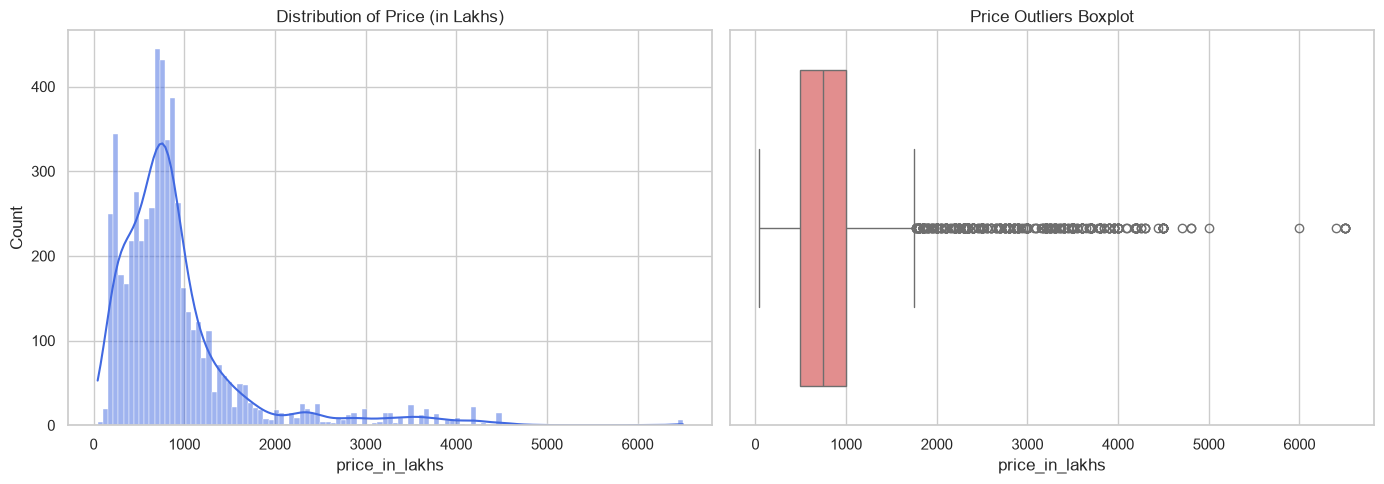

In [68]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Distribution
sns.histplot(df['price_in_lakhs'], kde=True, ax=axes[0], color='royalblue')
axes[0].set_title('Distribution of Price (in Lakhs)')

# Boxplot for Outliers
sns.boxplot(x=df['price_in_lakhs'], ax=axes[1], color='lightcoral')
axes[1].set_title('Price Outliers Boxplot')

plt.tight_layout()
plt.show()


In [73]:
df['price_in_lakhs'].max()

np.float64(6500.0)

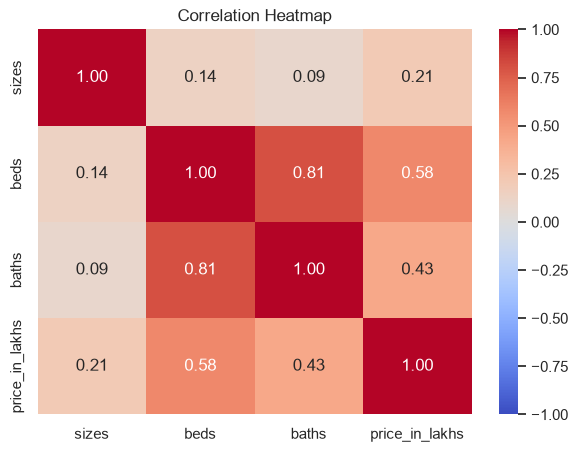

In [70]:
plt.figure(figsize=(7, 5))
numeric_cols = ['sizes', 'beds', 'baths', 'price_in_lakhs']
corr = df[numeric_cols].apply(pd.to_numeric, errors='coerce').corr()

sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1)
plt.title('Correlation Heatmap')
plt.show()


In [74]:
df.columns

Index(['locations', 'sizes', 'beds', 'baths', 'price_in_lakhs', 'size_label'], dtype='str')

In [81]:
df.drop(columns=['size_label'], inplace=True)

In [82]:
df.to_csv("cleand_csv")